# Figure per la sezione sull'oscillatore di Van der Pol

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def vdp(x, v, mu):
    """Derivate dell'oscillatore di Van der Pol: (dx/dtau, dv/dtau)."""
    return v, mu * (1.0 - x * x) * v - x

def integra(x0, v0, mu, dt, nsteps, stride=1):
    """Integra con RK4 e restituisce gli array tau, x, v (una riga ogni stride passi)."""
    n_out = nsteps // stride + 1
    tau = np.empty(n_out); X = np.empty(n_out); V = np.empty(n_out)
    x, v = x0, v0
    tau[0], X[0], V[0] = 0.0, x, v
    j = 1
    for n in range(1, nsteps + 1):
        k1x, k1v = vdp(x, v, mu)
        k2x, k2v = vdp(x + 0.5 * dt * k1x, v + 0.5 * dt * k1v, mu)
        k3x, k3v = vdp(x + 0.5 * dt * k2x, v + 0.5 * dt * k2v, mu)
        k4x, k4v = vdp(x + dt * k3x, v + dt * k3v, mu)
        x += dt / 6.0 * (k1x + 2 * k2x + 2 * k3x + k4x)
        v += dt / 6.0 * (k1v + 2 * k2v + 2 * k3v + k4v)
        if n % stride == 0:
            tau[j], X[j], V[j] = n * dt, x, v
            j += 1
    return tau, X, V

def periodo_ampiezza(tau, x, frazione=0.5):
    """Periodo (dagli zeri ascendenti, con interpolazione lineare) e ampiezza,
    usando solo l'ultima parte della traiettoria per escludere il transiente."""
    i0 = int(len(tau) * frazione)
    t, y = tau[i0:], x[i0:]
    i = np.where((y[:-1] < 0) & (y[1:] >= 0))[0]
    zeri = t[i] - y[i] * (t[i + 1] - t[i]) / (y[i + 1] - y[i])
    return np.mean(np.diff(zeri)), np.max(np.abs(y))

plt.rcParams.update({"font.size": 11, "axes.grid": True, "grid.alpha": 0.3})

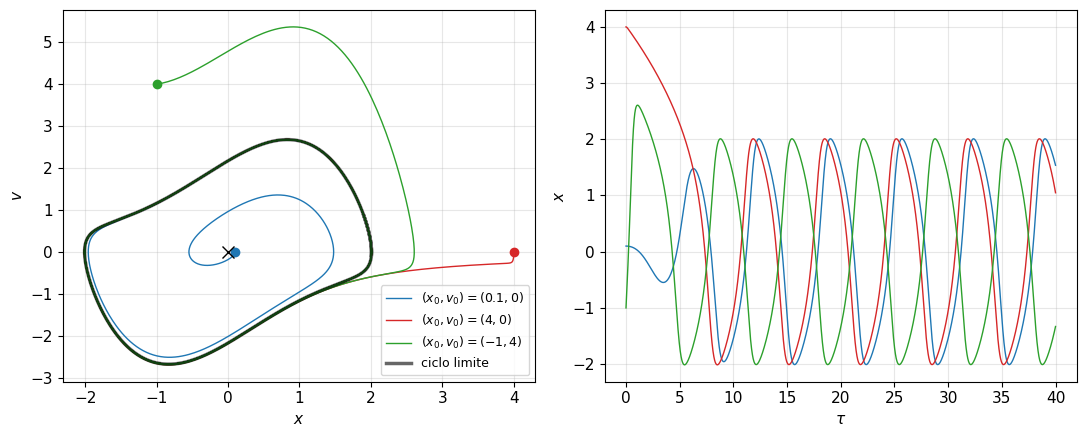

In [2]:
#| label: cell:vdp_phase
mu = 1.0
dt = 0.01
condizioni = [(0.1, 0.0, "C0", r"$(x_0, v_0) = (0.1, 0)$"),
              (4.0, 0.0, "C3", r"$(x_0, v_0) = (4, 0)$"),
              (-1.0, 4.0, "C2", r"$(x_0, v_0) = (-1, 4)$")]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
for x0, v0, c, lab in condizioni:
    tau, x, v = integra(x0, v0, mu, dt, 4000)
    ax1.plot(x, v, color=c, lw=1, label=lab)
    ax1.plot(x0, v0, "o", color=c)
    ax2.plot(tau, x, color=c, lw=1)
# ciclo limite: ultimo periodo di una traiettoria lunga
tau, x, v = integra(2.0, 0.0, mu, dt, 6000)
ax1.plot(x[-700:], v[-700:], "k", lw=2.5, alpha=0.6, label="ciclo limite")
ax1.plot(0, 0, "kx", ms=8)
ax1.set_xlabel("$x$"); ax1.set_ylabel("$v$"); ax1.legend(fontsize=9, loc="lower right")
ax2.set_xlabel(r"$\tau$"); ax2.set_ylabel("$x$")
fig.tight_layout()
plt.show()

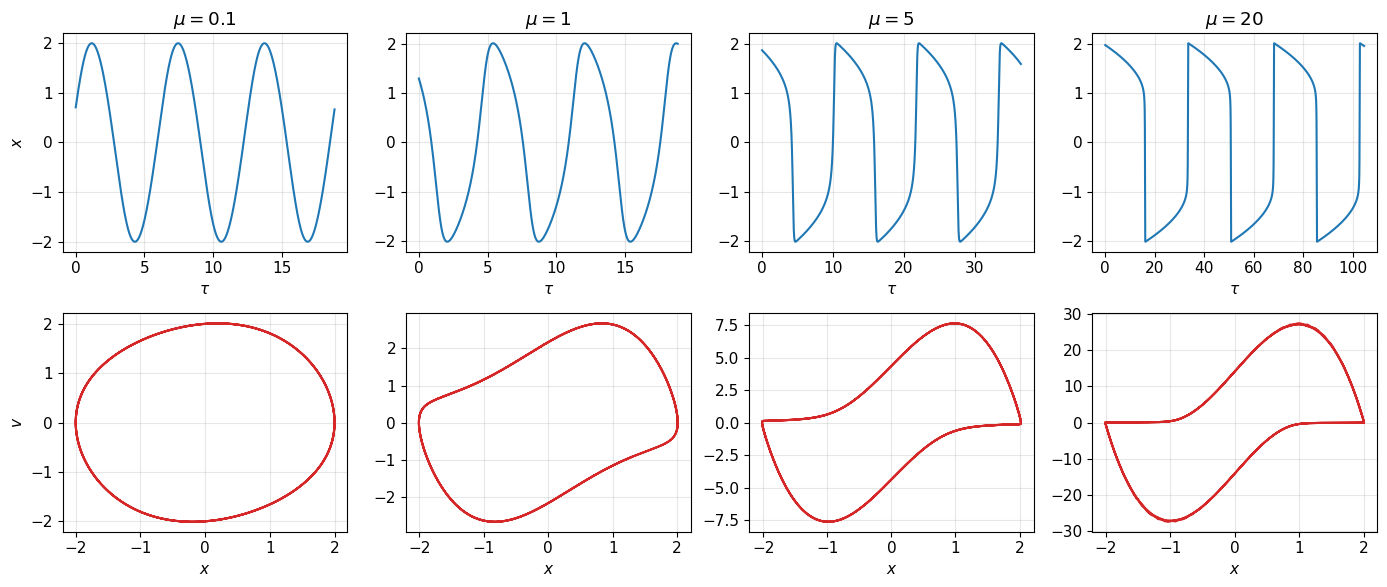

In [3]:
#| label: cell:vdp_mu
valori_mu = [0.1, 1.0, 5.0, 20.0]
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for k, mu in enumerate(valori_mu):
    T_stima = 2 * np.pi if mu < 2 else 1.614 * mu + 7.0 * mu ** (-1 / 3)
    t_tot = max(200.0, 8 * T_stima)
    tau, x, v = integra(2.0, 0.0, mu, 0.01, int(t_tot / 0.01))
    m = tau > tau[-1] - 3 * T_stima          # ultimi tre periodi
    axes[0, k].plot(tau[m] - tau[m][0], x[m], "C0")
    axes[0, k].set_title(rf"$\mu = {mu:g}$")
    axes[0, k].set_xlabel(r"$\tau$")
    axes[1, k].plot(x[m], v[m], "C3")
    axes[1, k].set_xlabel("$x$")
axes[0, 0].set_ylabel("$x$"); axes[1, 0].set_ylabel("$v$")
fig.tight_layout()
plt.show()

mu =   0.1   T =   6.28711   A = 2.00010
mu =   0.2   T =   6.29888   A = 2.00041
mu =   0.5   T =   6.38068   A = 2.00249
mu =     1   T =   6.66329   A = 2.00862
mu =     2   T =   7.62987   A = 2.01989
mu =     3   T =   8.85910   A = 2.02330
mu =     5   T =  11.61223   A = 2.02151
mu =     7   T =  14.53977   A = 2.01821
mu =    10   T =  19.07844   A = 2.01429
mu =    15   T =  26.82622   A = 2.01020
mu =    20   T =  34.68416   A = 2.00782
mu =    30   T =  50.54407   A = 2.00517
mu =    50   T =  82.51263   A = 2.00298


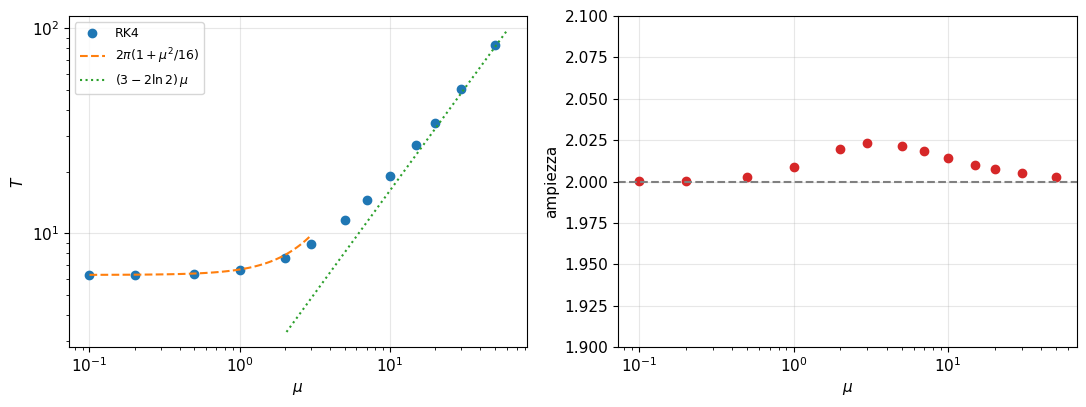

In [9]:
valori_mu = np.array([0.1, 0.2, 0.5, 1, 2, 3, 5, 7, 10, 15, 20, 30, 50])
T = np.empty(len(valori_mu)); A = np.empty(len(valori_mu))
for k, mu in enumerate(valori_mu):
    dt = 0.01 if mu <= 20 else 0.004
    T_stima = 2 * np.pi if mu < 2 else 1.614 * mu + 7.0 * mu ** (-1 / 3)
    t_tot = max(300.0, 12 * T_stima)
    tau, x, v = integra(2.0, 0.0, mu, dt, int(t_tot / dt), stride=1)
    T[k], A[k] = periodo_ampiezza(tau, x)
    print(f"mu = {mu:5g}   T = {T[k]:9.5f}   A = {A[k]:.5f}")

mm = np.logspace(-1, np.log10(60), 200)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
ax1.plot(valori_mu, T, "o", color="C0", label="RK4")
ax1.plot(mm[mm < 3], 2 * np.pi * (1 + mm[mm < 3] ** 2 / 16), "--", color="C1",
         label=r"$2\pi(1 + \mu^2/16)$")
ax1.plot(mm[mm > 2], (3 - 2 * np.log(2)) * mm[mm > 2], ":", color="C2",
         label=r"$(3 - 2\ln 2)\,\mu$")
ax1.set_xscale("log"); ax1.set_yscale("log")
ax1.set_xlabel(r"$\mu$"); ax1.set_ylabel("$T$"); ax1.legend(fontsize=9)
ax2.plot(valori_mu, A, "o", color="C3")
ax2.axhline(2, color="gray", ls="--")
ax2.set_xscale("log"); ax2.set_ylim(1.9, 2.1)
ax2.set_xlabel(r"$\mu$"); ax2.set_ylabel("ampiezza")
fig.tight_layout()

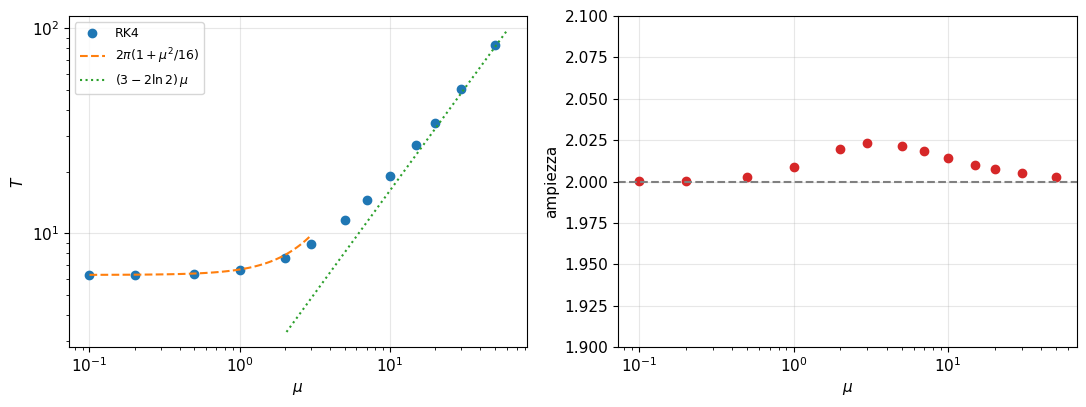

In [11]:
#| label: cell:vdp_period
fig

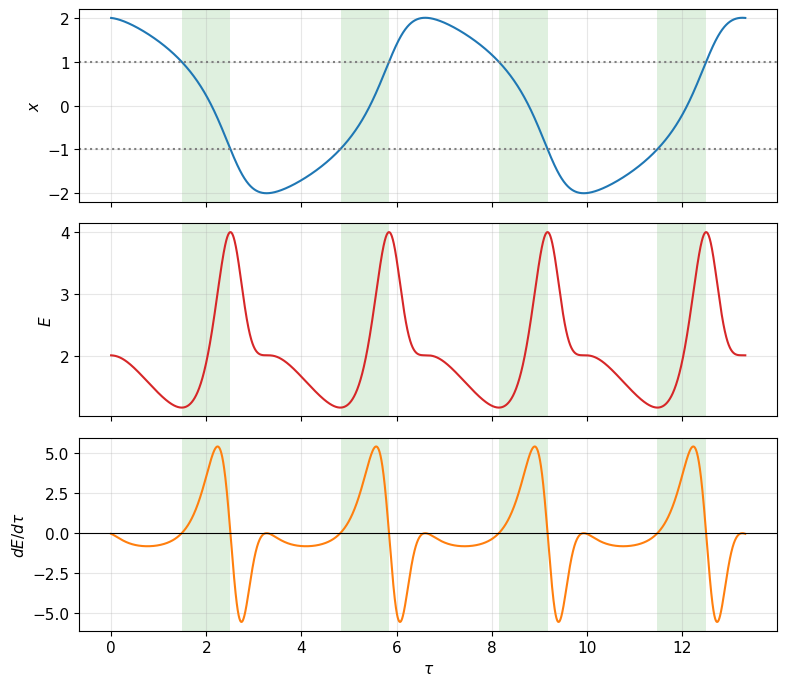

In [5]:
#| label: cell:vdp_energy
mu = 1.0
dt = 0.005
tau, x, v = integra(2.0, 0.0, mu, dt, int(100 / dt))
T, _ = periodo_ampiezza(tau, x)
m = tau > tau[-1] - 2 * T
t, xx, vv = tau[m] - tau[m][0], x[m], v[m]
E = 0.5 * (xx ** 2 + vv ** 2)
dEdt = mu * (1 - xx ** 2) * vv ** 2

fig, axes = plt.subplots(3, 1, figsize=(8, 7), sharex=True)
for ax in axes:   # fasi in cui il sistema acquista energia (|x| < 1)
    ax.fill_between(t, 0, 1, where=np.abs(xx) < 1, color="C2", alpha=0.15,
                    transform=ax.get_xaxis_transform(), lw=0)
axes[0].plot(t, xx, "C0"); axes[0].axhline(1, color="gray", ls=":"); axes[0].axhline(-1, color="gray", ls=":")
axes[0].set_ylabel("$x$")
axes[1].plot(t, E, "C3"); axes[1].set_ylabel("$E$")
axes[2].plot(t, dEdt, "C1"); axes[2].axhline(0, color="k", lw=0.8)
axes[2].set_ylabel(r"$dE/d\tau$"); axes[2].set_xlabel(r"$\tau$")
fig.tight_layout()
plt.show()

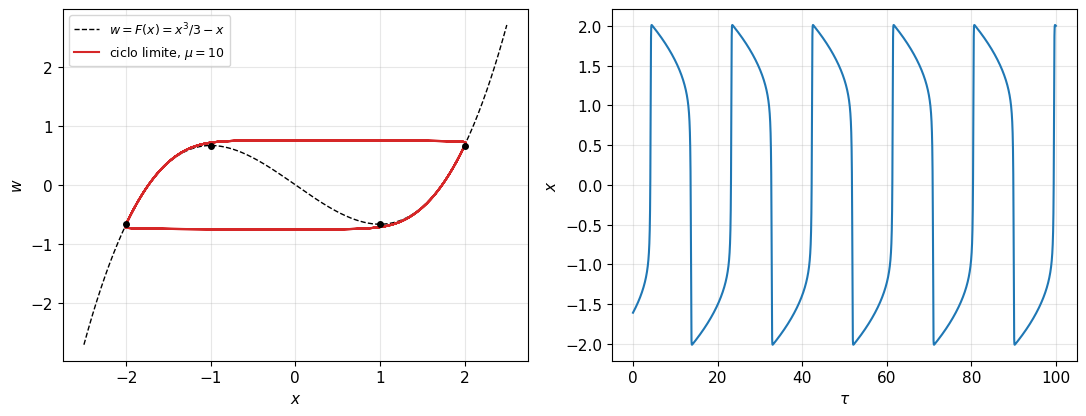

In [6]:
#| label: cell:vdp_lienard
mu = 10.0
dt = 0.005
tau, x, v = integra(0.5, 0.0, mu, dt, int(200 / dt))
F = lambda y: y ** 3 / 3 - y
w = v / mu + F(x)
m = tau > 100                        # ciclo limite, dopo il transiente
xs = np.linspace(-2.5, 2.5, 400)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.3))
ax1.plot(xs, F(xs), "k--", lw=1, label=r"$w = F(x) = x^3/3 - x$")
ax1.plot(x[m], w[m], "C3", lw=1.5, label=r"ciclo limite, $\mu = 10$")
for xp, wp in [(2, 2 / 3), (1, -2 / 3), (-2, -2 / 3), (-1, 2 / 3)]:
    ax1.plot(xp, wp, "ko", ms=4)
ax1.set_xlabel("$x$"); ax1.set_ylabel("$w$"); ax1.legend(fontsize=9)
ax2.plot(tau[m] - tau[m][0], x[m], "C0")
ax2.set_xlabel(r"$\tau$"); ax2.set_ylabel("$x$")
fig.tight_layout()
plt.show()

In [7]:
# Passo massimo per cui RK4 resta stabile, al variare di mu
for mu in [5, 10, 20, 50, 100]:
    stabili = []
    for dt in [0.2, 0.1, 0.07, 0.05, 0.04, 0.03, 0.02, 0.015, 0.01, 0.007, 0.005]:
        with np.errstate(all="ignore"):
            tau, x, v = integra(0.5, 0.0, mu, dt, int((5 * 1.614 * mu + 30) / dt), stride=10)
        if np.all(np.isfinite(x)) and np.max(np.abs(x)) < 3:
            stabili.append(dt)
    print(f"mu = {mu:4d}   dt_max ~ {max(stabili):.3f}   mu * dt_max ~ {mu * max(stabili):.2f}")

mu =    5   dt_max ~ 0.100   mu * dt_max ~ 0.50
mu =   10   dt_max ~ 0.070   mu * dt_max ~ 0.70
mu =   20   dt_max ~ 0.040   mu * dt_max ~ 0.80


mu =   50   dt_max ~ 0.015   mu * dt_max ~ 0.75


mu =  100   dt_max ~ 0.007   mu * dt_max ~ 0.70
